# Give Me Some Credit - EDA (feature × target 교차 분석)

- **target**: `연체여부` (2년 안에 90일 이상 연체했나? 1 = 연체)
- **feature**: 나머지 10개 열
- 순서: 데이터 확인 → target 분포 → feature 하나씩 × target → feature끼리 (의심 가는 쌍만)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rc('font', family='Malgun Gothic')      # 한글 폰트 (Windows)
plt.rc('axes', unicode_minus=False)          # 마이너스 기호 깨짐 방지

df = pd.read_csv('cs-training.csv', index_col=0)   # 첫 열은 Id라서 인덱스로
# 영문 컬럼명 → 한글 (cs-test.csv를 불러올 때도 똑같이 rename 해야 함)
COL_KR = {
    'SeriousDlqin2yrs': '연체여부',
    'RevolvingUtilizationOfUnsecuredLines': '신용한도사용률',
    'age': '나이',
    'NumberOfTime30-59DaysPastDueNotWorse': '연체30_59일횟수',
    'DebtRatio': '부채비율',
    'MonthlyIncome': '월소득',
    'NumberOfOpenCreditLinesAndLoans': '대출카드수',
    'NumberOfTimes90DaysLate': '연체90일이상횟수',
    'NumberRealEstateLoansOrLines': '부동산대출수',
    'NumberOfTime60-89DaysPastDueNotWorse': '연체60_89일횟수',
    'NumberOfDependents': '부양가족수',
}
df = df.rename(columns=COL_KR)
TARGET = '연체여부'
FEATURES = df.columns.drop(TARGET).tolist()

print(df.shape)
df.head()

(150000, 11)


,연체여부,신용한도사용률,나이,연체30_59일횟수,부채비율,월소득,대출카드수,연체90일이상횟수,부동산대출수,연체60_89일횟수,부양가족수
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 1. 데이터 기본 확인

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   연체여부        150000 non-null  int64  
 1   신용한도사용률     150000 non-null  float64
 2   나이          150000 non-null  int64  
 3   연체30_59일횟수  150000 non-null  int64  
 4   부채비율        150000 non-null  float64
 5   월소득         120269 non-null  float64
 6   대출카드수       150000 non-null  int64  
 7   연체90일이상횟수   150000 non-null  int64  
 8   부동산대출수      150000 non-null  int64  
 9   연체60_89일횟수  150000 non-null  int64  
 10  부양가족수       146076 non-null  float64
dtypes: float64(4), int64(7)
memory usage: 13.7 MB


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
연체여부,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
신용한도사용률,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
나이,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
연체30_59일횟수,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
부채비율,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
월소득,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
대출카드수,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
연체90일이상횟수,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
부동산대출수,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
연체60_89일횟수,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


In [4]:
# 결측치
na = df.isna().sum()
na[na > 0].to_frame('결측 개수').assign(비율=lambda x: (x['결측 개수'] / len(df)).round(3))

,결측 개수,비율
월소득,29731,0.198
부양가족수,3924,0.026


## 2. target 분포

연체(1)가 아주 적은 **불균형 데이터**입니다. 전부 0으로 찍어도 정확도가 93%라서, 평가는 정확도 대신 **AUC**로 합니다.

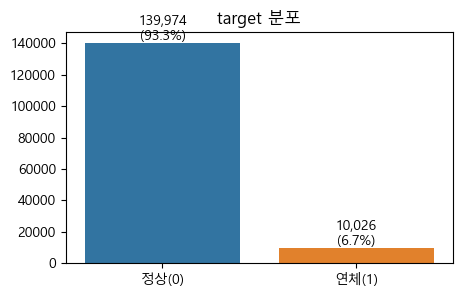

In [5]:
counts = df[TARGET].value_counts()
fig, ax = plt.subplots(figsize=(5, 3))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}\n({v / len(df):.1%})', ha='center', va='bottom')
ax.set_xticklabels(['정상(0)', '연체(1)'])
ax.set_title('target 분포')
plt.show()

## 3. feature × target 교차 분석 (하나씩)

각 feature마다 그래프 2개를 그립니다.

- **왼쪽: 분포 비교.** 정상(0)과 연체(1) 그룹의 값 분포가 다르면 쓸모 있는 feature입니다. 극단값 때문에 그래프가 찌그러지지 않도록 **상위 1%는 잘라서** 그립니다.
- **오른쪽: 구간별 연체율.** 값을 구간으로 나눠 구간마다 연체율을 계산합니다. 막대가 한쪽으로 기울면 강한 힌트, 평평하면 약한 힌트입니다. 빨간 점선은 전체 평균 연체율이에요.

결측치는 오른쪽 그래프에 `결측`이라는 별도 막대로 표시합니다.

In [6]:
from sklearn.metrics import roc_auc_score

BASE_RATE = df[TARGET].mean()

def single_auc(col):
    # feature 하나만으로 target을 얼마나 맞히는지 (0.5 = 동전 던지기, 1.0 = 완벽)
    s = df[col].fillna(df[col].median())
    auc = roc_auc_score(df[TARGET], s)
    return max(auc, 1 - auc)

def make_bins(col, max_count=None):
    s = df[col]
    if max_count is not None:
        # 횟수형 변수: 값 그대로 쓰되 max_count 이상은 한 구간으로 묶기
        labels = s.clip(upper=max_count).astype('Int64').astype(str)
        labels = labels.replace(str(max_count), f'{max_count}+')
        order = [str(i) for i in range(max_count)] + [f'{max_count}+']
    else:
        # 연속형 변수: 값 크기순으로 10구간 (같은 값이 많으면 구간 수가 줄어듦)
        binned = pd.qcut(s, q=10, duplicates='drop')
        order = [str(c) for c in binned.cat.categories]
        labels = binned.astype(str)
    labels = labels.where(s.notna(), '결측')
    if s.isna().any():
        order.append('결측')
    return labels, order

def plot_feature(col, max_count=None, log=False):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    # 왼쪽: 정상 vs 연체 분포
    upper = df[col].quantile(0.99)
    clipped = df[df[col] <= upper]
    if log:
        clipped = clipped[clipped[col] > 0]     # 로그 스케일은 0 이하를 그릴 수 없음
    if max_count is not None:
        sns.countplot(data=clipped, x=col, hue=TARGET, ax=axes[0])
        axes[0].set_yscale('log')
        axes[0].set_ylabel('count (log)')
    else:
        sns.histplot(data=clipped, x=col, hue=TARGET, stat='density', common_norm=False,
                     bins=50, element='step', log_scale=(log, False), ax=axes[0])
    axes[0].set_title(f'{col} 분포 (상위 1% 제외, 기준 {upper:,.2f})')

    # 오른쪽: 구간별 연체율
    labels, order = make_bins(col, max_count)
    stats = df.groupby(labels)[TARGET].agg(['mean', 'size']).reindex(order).dropna()
    sns.barplot(x=stats.index, y=stats['mean'], color='steelblue', ax=axes[1])
    axes[1].axhline(BASE_RATE, color='red', ls='--', lw=1, label=f'전체 평균 {BASE_RATE:.1%}')
    for i, (rate, n) in enumerate(zip(stats['mean'], stats['size'])):
        axes[1].text(i, rate, f'{rate:.1%}\nn={n:,}', ha='center', va='bottom', fontsize=7)
    axes[1].set_ylabel('연체율')
    axes[1].set_xlabel('')
    axes[1].tick_params(axis='x', rotation=45, labelsize=8)
    axes[1].set_ylim(0, stats['mean'].max() * 1.3)
    axes[1].legend(loc='best')
    axes[1].set_title(f'{col} 구간별 연체율 (단독 AUC = {single_auc(col):.3f})')

    plt.tight_layout()
    plt.show()

    print(df[col].describe().round(3).to_string())

### 3-1. `신용한도사용률`

신용한도 사용률 (신용카드 등 무담보 대출 잔액 ÷ 한도). 비율이라 보통 0~1 사이여야 하는데, 1을 넘는 값과 수만 단위 극단값이 섞여 있습니다.

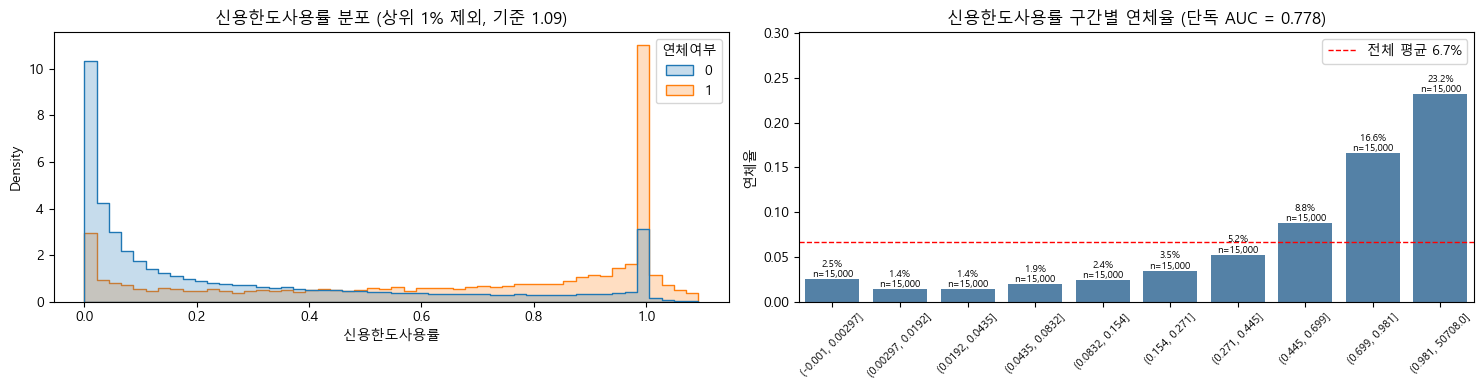

count    150000.000
mean          6.048
std         249.755
min           0.000
25%           0.030
50%           0.154
75%           0.559
max       50708.000


In [7]:
plot_feature('신용한도사용률')

In [8]:
# 1 초과 값은 얼마나 있고, 그 사람들의 연체율은?
over = df['신용한도사용률'] > 1
print('1 초과:', over.sum(), '명')
print('1 이하 연체율:', round(df.loc[~over, TARGET].mean(), 3))
print('1 초과 연체율:', round(df.loc[over, TARGET].mean(), 3))
print('10 초과 연체율:', round(df.loc[df['신용한도사용률'] > 10, TARGET].mean(), 3))

1 초과: 3321 명
1 이하 연체율: 0.06
1 초과 연체율: 0.372
10 초과 연체율: 0.071


### 3-2. `나이`

나이. 젊을수록 연체율이 높을 것으로 예상됩니다. 0살 같은 입력 오류가 있는지도 확인합니다.

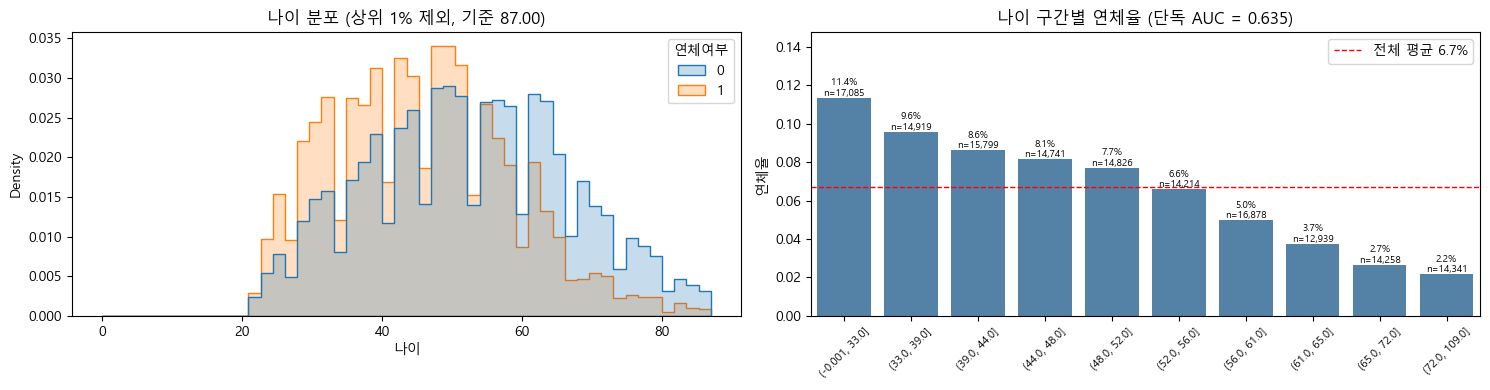

count    150000.000
mean         52.295
std          14.772
min           0.000
25%          41.000
50%          52.000
75%          63.000
max         109.000


In [9]:
plot_feature('나이')

In [10]:
print('나이 0:', (df['나이'] == 0).sum(), '명')
print('나이 21 미만:', (df['나이'] < 21).sum(), '명')

나이 0: 1 명
나이 21 미만: 1 명


### 3-3. `연체30_59일횟수`

최근 2년간 30~59일 연체 횟수. 대부분 0~몇 회인데 **96, 98** 같은 값이 있어서 실제 횟수가 아닌 코드값으로 의심됩니다. 오른쪽 그래프는 6회 이상을 한 구간으로 묶었습니다.

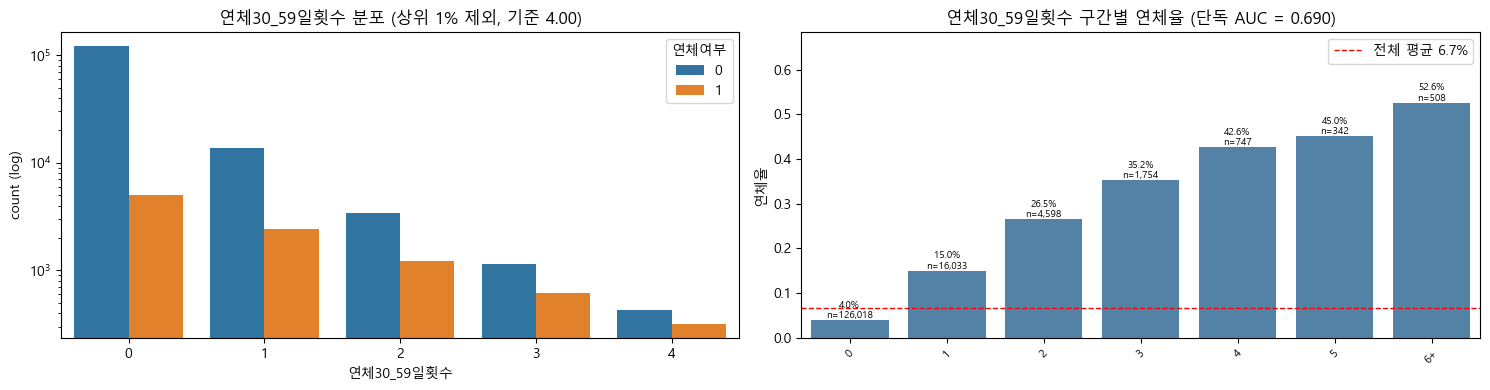

count    150000.000
mean          0.421
std           4.193
min           0.000
25%           0.000
50%           0.000
75%           0.000
max          98.000


In [11]:
plot_feature('연체30_59일횟수', max_count=6)

In [12]:
df['연체30_59일횟수'].value_counts().sort_index()

0     126018
1      16033
2       4598
3       1754
4        747
5        342
6        140
7         54
8         25
9         12
10         4
11         1
12         2
13         1
96         5
98       264
Name: 연체30_59일횟수, dtype: int64

### 3-4. `부채비율`

부채 비율 (월 부채 상환액 ÷ 월소득). 비율인데 1 초과가 아주 많습니다. 소득을 모르는 사람은 비율 대신 금액이 들어갔을 가능성이 있어서, 아래 4장에서 `월소득` 결측 여부와 교차해 봅니다.

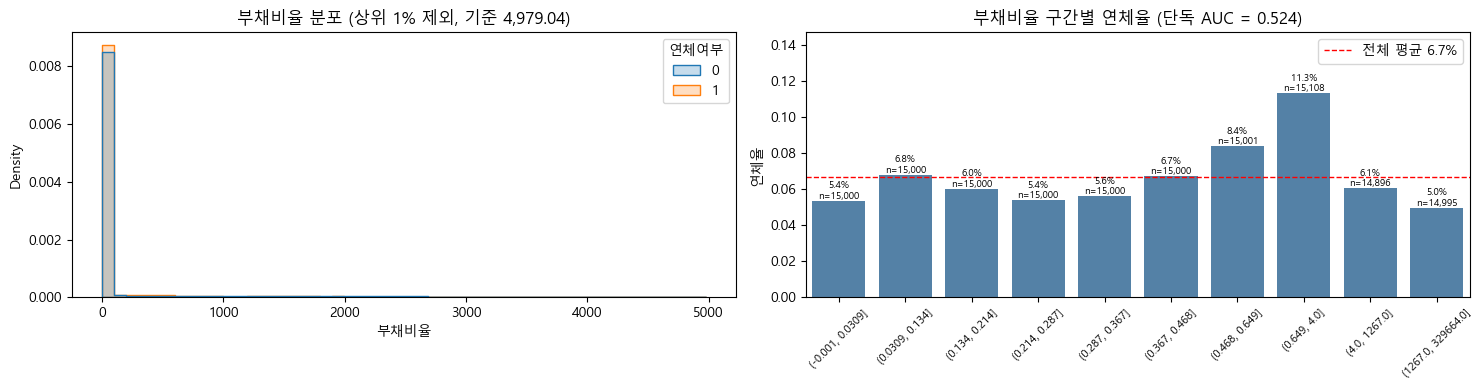

count    150000.000
mean        353.005
std        2037.819
min           0.000
25%           0.175
50%           0.367
75%           0.868
max      329664.000


In [13]:
plot_feature('부채비율')

### 3-5. `월소득`

월소득. 약 20%가 결측입니다. 오른쪽 그래프의 `결측` 막대로 결측자의 연체율도 같이 봅니다. 값이 오른쪽으로 길게 늘어져 있어서 왼쪽 그래프는 로그 스케일로 그립니다.

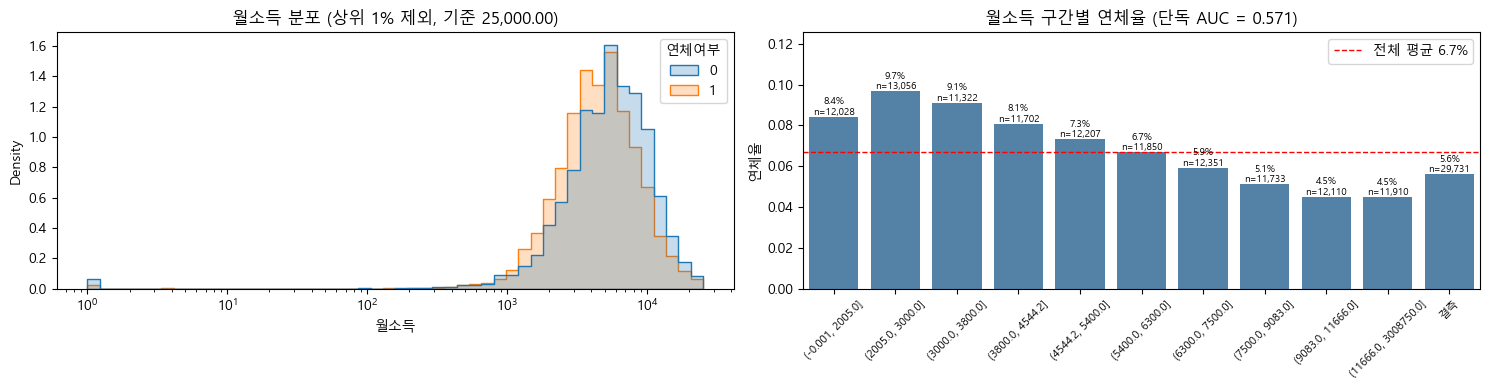

count     120269.000
mean        6670.221
std        14384.674
min            0.000
25%         3400.000
50%         5400.000
75%         8249.000
max      3008750.000


In [14]:
plot_feature('월소득', log=True)

### 3-6. `대출카드수`

보유 중인 대출·신용카드 개수.

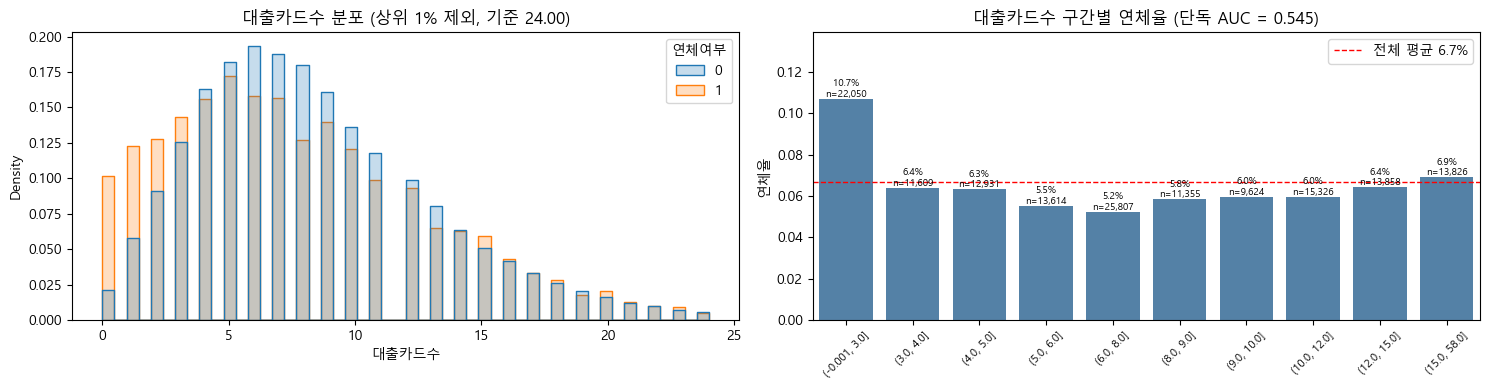

count    150000.000
mean          8.453
std           5.146
min           0.000
25%           5.000
50%           8.000
75%          11.000
max          58.000


In [15]:
plot_feature('대출카드수')

### 3-7. `연체90일이상횟수`

90일 이상 연체 횟수. 30-59일 열과 마찬가지로 96, 98 값을 확인합니다.

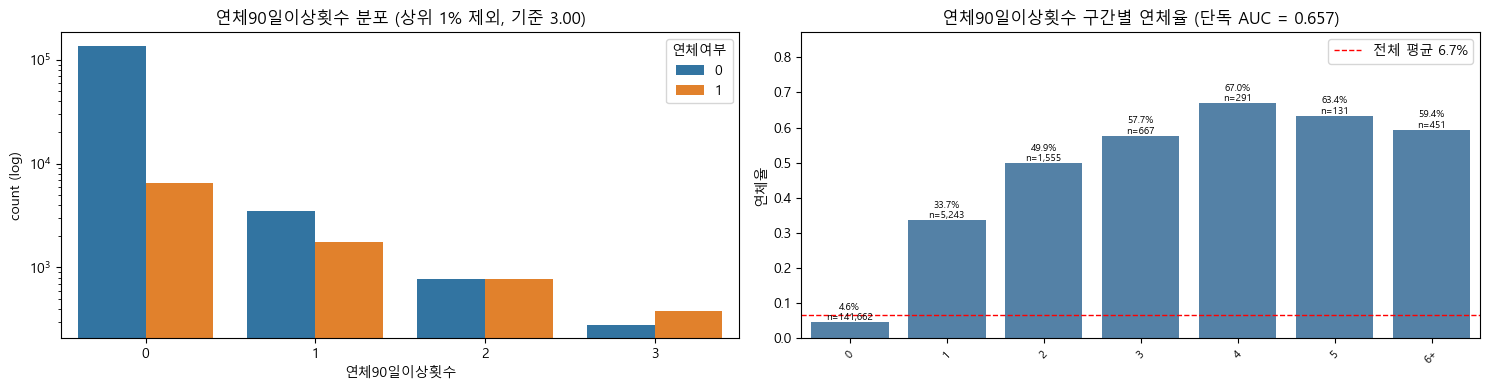

count    150000.000
mean          0.266
std           4.169
min           0.000
25%           0.000
50%           0.000
75%           0.000
max          98.000


In [16]:
plot_feature('연체90일이상횟수', max_count=6)

In [17]:
df['연체90일이상횟수'].value_counts().sort_index()

0     141662
1       5243
2       1555
3        667
4        291
5        131
6         80
7         38
8         21
9         19
10         8
11         5
12         2
13         4
14         2
15         2
17         1
96         5
98       264
Name: 연체90일이상횟수, dtype: int64

### 3-8. `부동산대출수`

부동산 담보 대출 개수.

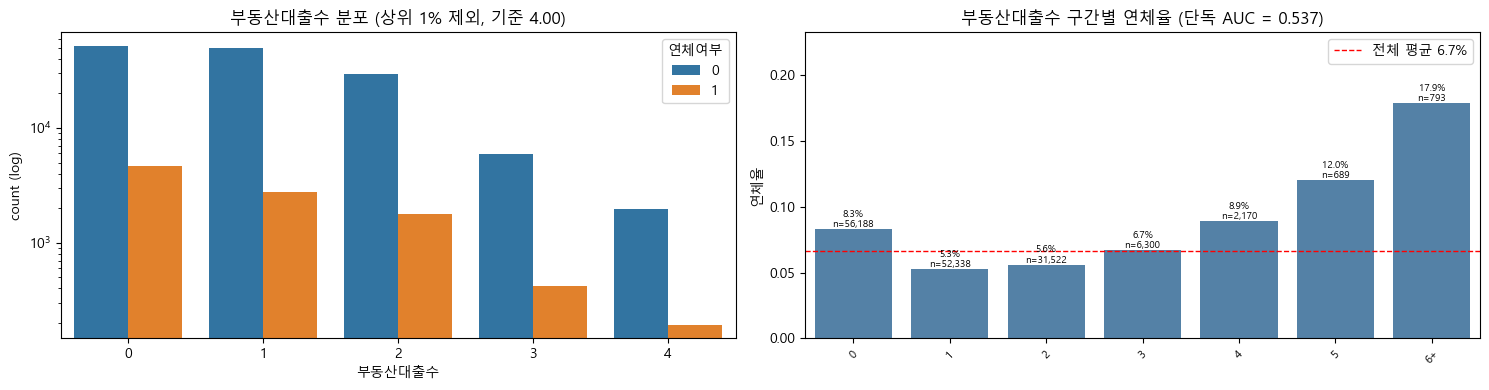

count    150000.000
mean          1.018
std           1.130
min           0.000
25%           0.000
50%           1.000
75%           2.000
max          54.000


In [18]:
plot_feature('부동산대출수', max_count=6)

### 3-9. `연체60_89일횟수`

최근 2년간 60~89일 연체 횟수.

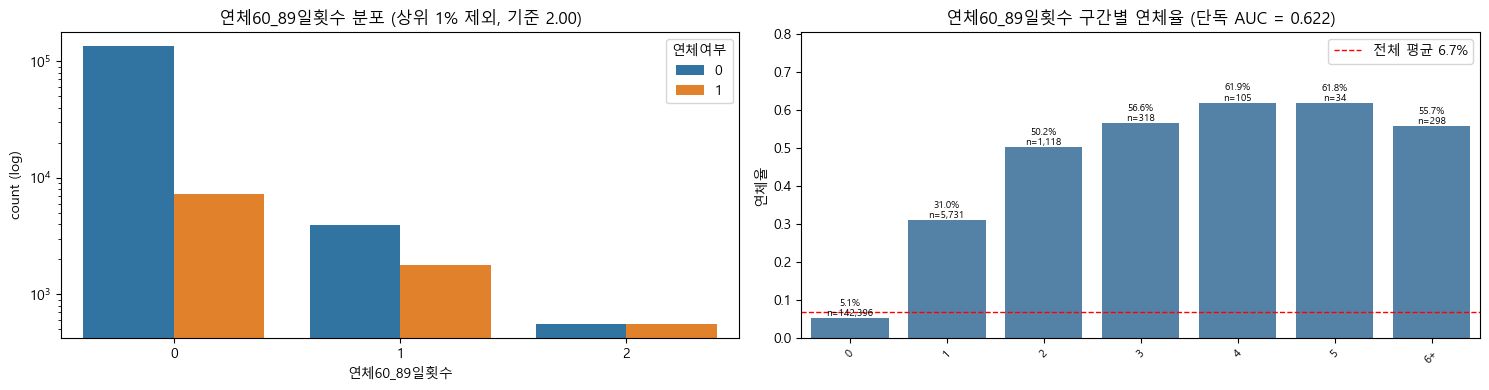

count    150000.000
mean          0.240
std           4.155
min           0.000
25%           0.000
50%           0.000
75%           0.000
max          98.000


In [19]:
plot_feature('연체60_89일횟수', max_count=6)

In [20]:
df['연체60_89일횟수'].value_counts().sort_index()

0     142396
1       5731
2       1118
3        318
4        105
5         34
6         16
7          9
8          2
9          1
11         1
96         5
98       264
Name: 연체60_89일횟수, dtype: int64

### 3-10. `부양가족수`

부양가족 수 (본인 제외). 약 2.6%가 결측입니다.

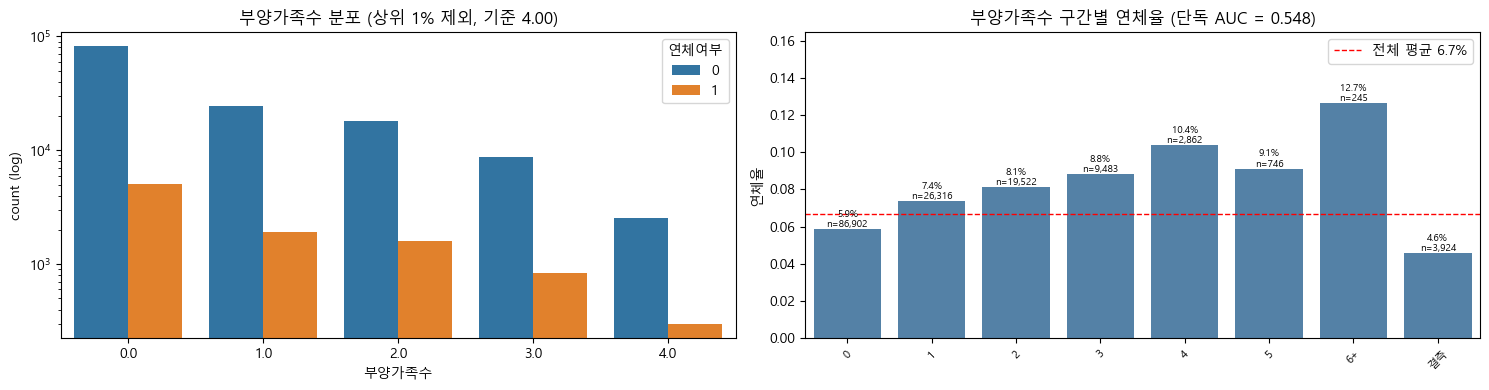

count    146076.000
mean          0.757
std           1.115
min           0.000
25%           0.000
50%           0.000
75%           1.000
max          20.000


In [21]:
plot_feature('부양가족수', max_count=6)

### 3-11. feature별 단독 AUC 요약

feature 하나만으로 target을 얼마나 맞힐 수 있는지 한눈에 비교합니다. 이 순서가 "어떤 feature를 더 깊게 볼지"의 기준이 됩니다.

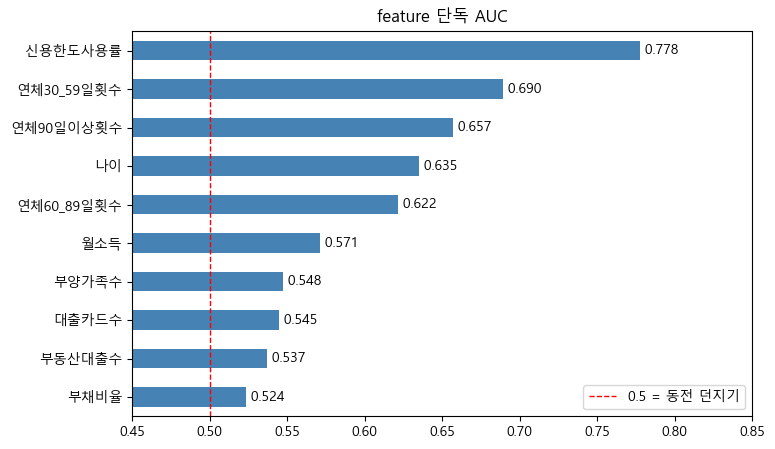

In [22]:
auc_df = pd.Series({col: single_auc(col) for col in FEATURES}).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
auc_df.plot(kind='barh', color='steelblue', ax=ax)
ax.axvline(0.5, color='red', ls='--', lw=1, label='0.5 = 동전 던지기')
for i, v in enumerate(auc_df):
    ax.text(v, i, f' {v:.3f}', va='center')
ax.set_xlim(0.45, 0.85)
ax.set_title('feature 단독 AUC')
ax.legend()
plt.show()

## 4. feature × feature 교차 분석 (의심 가는 쌍만)

10개 feature의 모든 쌍(45쌍)을 다 볼 필요는 없습니다. 상관계수 히트맵으로 전체를 한 번 훑고, 이상한 쌍만 파고듭니다.

### 4-1. 상관계수 히트맵

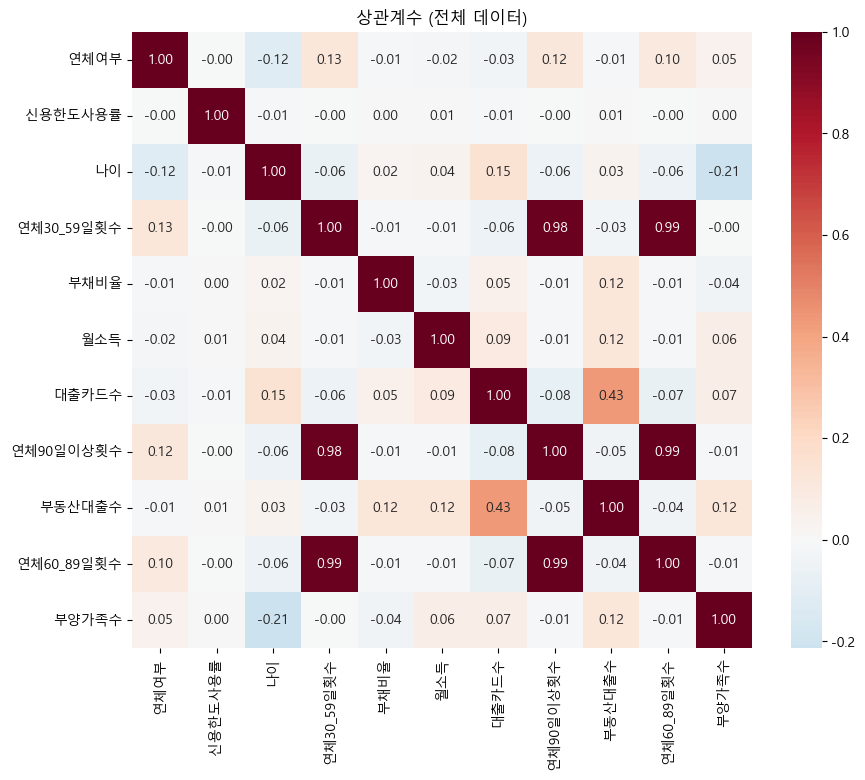

In [23]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('상관계수 (전체 데이터)')
plt.show()

### 4-2. 연체 횟수 3개 열: 96·98 코드값의 영향

히트맵에서 연체 횟수 3개 열의 상관계수가 0.98~0.99로 거의 같은 열처럼 보입니다. 96·98 값을 가진 사람들이 세 열 모두에 똑같이 들어가 있기 때문인지 확인합니다.

96·98 값을 가진 사람: 269 명
그중 세 열 값이 모두 같은 사람: 269 명
이 사람들의 연체율: 0.546 / 전체 평균: 0.067


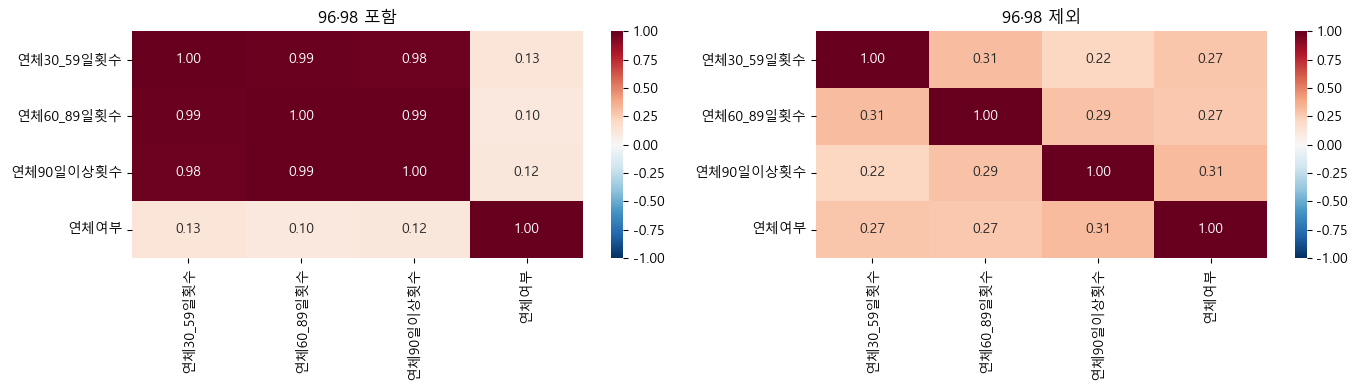

In [24]:
late_cols = ['연체30_59일횟수', '연체60_89일횟수', '연체90일이상횟수']
is_code = df['연체90일이상횟수'] >= 96

print('96·98 값을 가진 사람:', is_code.sum(), '명')
print('그중 세 열 값이 모두 같은 사람:', (df.loc[is_code, late_cols].nunique(axis=1) == 1).sum(), '명')
print('이 사람들의 연체율:', round(df.loc[is_code, TARGET].mean(), 3), '/ 전체 평균:', round(BASE_RATE, 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(df[late_cols + [TARGET]].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('96·98 포함')
sns.heatmap(df.loc[~is_code, late_cols + [TARGET]].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('96·98 제외')
plt.tight_layout()
plt.show()

### 4-3. `부채비율` × `월소득` 결측 여부

부채비율의 단독 AUC가 0.5 근처로 거의 의미가 없게 나왔습니다. 소득이 결측인 사람은 부채비율에 비율이 아닌 금액이 들어간 것은 아닌지 확인합니다.

          count    mean      std  min     25%     50%      75%       max
월소득                                                                     
소득 결측   29731.0  1673.4  4248.37  0.0  123.00  1159.0  2382.00  329664.0
소득 있음  120269.0    26.6   424.45  0.0    0.14     0.3     0.48   61106.5


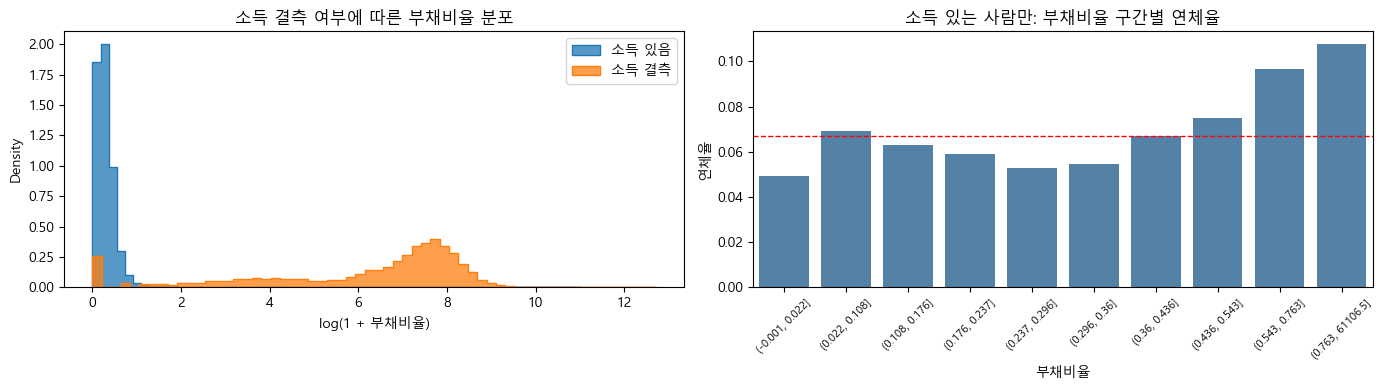

소득 있는 사람만 부채비율 단독 AUC: 0.561


In [25]:
income_na = df['월소득'].isna()

print(df.groupby(income_na.map({True: '소득 결측', False: '소득 있음'}))['부채비율'].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for is_na, name in [(False, '소득 있음'), (True, '소득 결측')]:
    sns.histplot(np.log1p(df.loc[income_na == is_na, '부채비율']), bins=60, stat='density',
                 element='step', label=name, ax=axes[0])
axes[0].set_xlabel('log(1 + 부채비율)')
axes[0].set_title('소득 결측 여부에 따른 부채비율 분포')
axes[0].legend()

# 소득 있는 사람만 놓고 부채비율 구간별 연체율
sub = df[~income_na]
bins = pd.qcut(sub['부채비율'], q=10)
rate = sub.groupby(bins)[TARGET].mean()
sns.barplot(x=rate.index.astype(str), y=rate.values, color='steelblue', ax=axes[1])
axes[1].axhline(BASE_RATE, color='red', ls='--', lw=1)
axes[1].tick_params(axis='x', rotation=45, labelsize=8)
axes[1].set_ylabel('연체율')
axes[1].set_title('소득 있는 사람만: 부채비율 구간별 연체율')
plt.tight_layout()
plt.show()

auc_with_income = roc_auc_score(sub[TARGET], sub['부채비율'])
print('소득 있는 사람만 부채비율 단독 AUC:', round(max(auc_with_income, 1 - auc_with_income), 3))

### 4-4. `나이` × `신용한도사용률`: 두 feature를 같이 보면?

가장 강한 feature(신용한도 사용률)와 나이를 함께 놓고 칸마다 연체율을 칠합니다. 색이 한 방향으로만 변하지 않고 섞여 있으면 두 feature가 서로 다른 정보를 주고 있다는 뜻입니다.

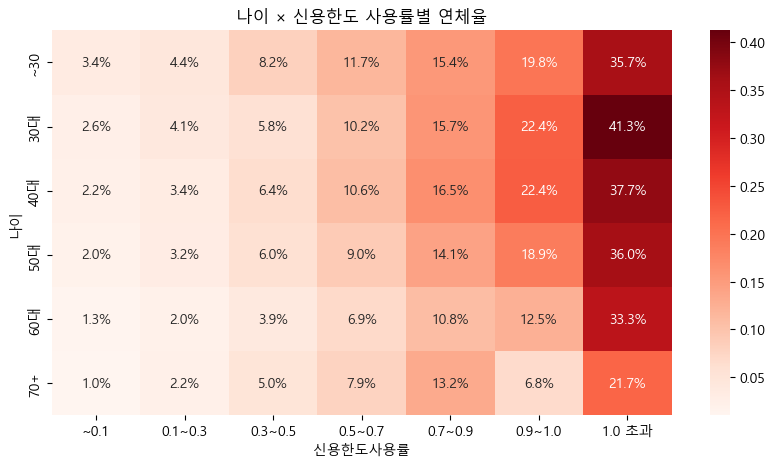

In [26]:
age_bin = pd.cut(df['나이'], [0, 30, 40, 50, 60, 70, 120], labels=['~30', '30대', '40대', '50대', '60대', '70+'])
rev_bin = pd.cut(df['신용한도사용률'], [-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, np.inf],
                 labels=['~0.1', '0.1~0.3', '0.3~0.5', '0.5~0.7', '0.7~0.9', '0.9~1.0', '1.0 초과'])

pivot = df.pivot_table(index=age_bin, columns=rev_bin, values=TARGET, aggfunc='mean')
plt.figure(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt='.1%', cmap='Reds')
plt.title('나이 × 신용한도 사용률별 연체율')
plt.xlabel('신용한도사용률')
plt.ylabel('나이')
plt.show()

### 4-5. `월소득` × `부양가족수`

같은 소득이라도 부양가족이 많으면 형편이 더 빠듯할 수 있습니다. "1인당 소득" 파생 변수를 만들 근거가 되는지 봅니다.

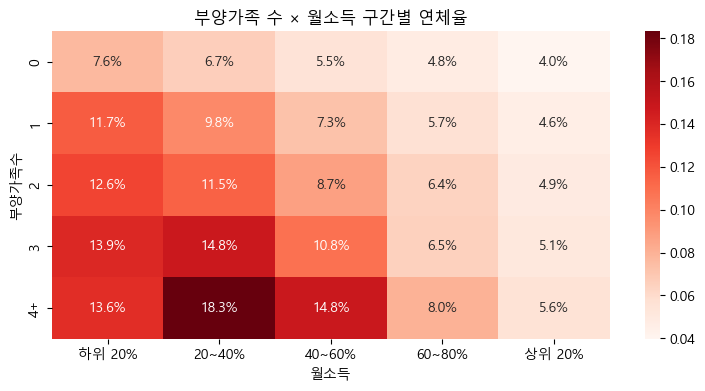

월소득 단독 AUC: 0.576
1인당 소득 단독 AUC  : 0.594


In [27]:
sub = df.dropna(subset=['월소득', '부양가족수'])
inc_bin = pd.qcut(sub['월소득'], q=5, labels=['하위 20%', '20~40%', '40~60%', '60~80%', '상위 20%'])
dep_bin = sub['부양가족수'].clip(upper=4).astype(int).astype(str).replace('4', '4+')

pivot = sub.pivot_table(index=dep_bin, columns=inc_bin, values=TARGET, aggfunc='mean')
plt.figure(figsize=(9, 4))
sns.heatmap(pivot, annot=True, fmt='.1%', cmap='Reds')
plt.title('부양가족 수 × 월소득 구간별 연체율')
plt.ylabel('부양가족수')
plt.xlabel('월소득')
plt.show()

income_per_person = sub['월소득'] / (sub['부양가족수'] + 1)
auc_pp = roc_auc_score(sub[TARGET], income_per_person)
auc_inc = roc_auc_score(sub[TARGET], sub['월소득'])
print('월소득 단독 AUC:', round(max(auc_inc, 1 - auc_inc), 3))
print('1인당 소득 단독 AUC  :', round(max(auc_pp, 1 - auc_pp), 3))

## 5. 정리 (그래프를 보고 직접 채워 넣기)

| 발견한 것 | 원인 추정 | 처리 방법 |
|---|---|---|
| 연체 횟수 열의 96·98 값 | | |
| 신용한도사용률 1 초과 / 극단값 | | |
| 부채비율 1 초과 (소득 결측과 관련?) | | |
| 월소득 결측 20% | | |
| 부양가족수 결측 | | |
| 나이 0 | | |
| 파생 변수 후보 | | |

여기서 정한 처리를 `cs-test.csv`에도 **똑같이** 적용해야 합니다.